# Lab02 — Đánh giá đầy đủ 5-fold cross-validation

**Aspect-level, 3 lớp**, dùng hai CSV chuẩn hóa có sẵn. Đây là lần chạy mới đủ 5 fold,
tách biệt kết quả holdout trong notebook cũ. Mỗi mô hình DL được khởi tạo và huấn luyện lại ở từng fold.
Tổng cộng 10 phương pháp × 5 fold = 50 lượt đánh giá outer; 25 mạng DL và 20 baseline được fit.

Mỗi fold có **inner-fit → inner-validation → outer-evaluation**. Inner-validation chọn epoch/trọng số ensemble;
outer-evaluation chỉ chấm điểm. Test chính thức giữ riêng. Báo cáo: [BAO_CAO_CV.md](BAO_CAO_CV.md).

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'run_cross_validation.py').exists():
    ROOT = ROOT / 'Lab02'
sys.path.insert(0, str(ROOT))
CV = ROOT / 'cross_validation'
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
completion = read_json(CV / 'results/completion.json')
assert completion['completed_folds'] == 5
display(completion)

{'completed_folds': 5,
 'methods_per_fold': 10,
 'total_outer_evaluations': 50,
 'development_rows': 3601,
 'oof_coverage': 'exactly once per development row',
 'elapsed_seconds_this_invocation': 860.873417499999,
 'selected': 'SoftVoting_Ensemble'}

## 1. Dữ liệu và cách chia

Train nguồn có 3.602 mẫu khía cạnh. Loại một mẫu trùng câu với test khỏi phần development;
3.601 mẫu còn lại tham gia đủ 5 fold. Test có 1.120 mẫu, giữ nguyên.
`StratifiedGroupKFold(5)` chia theo nhóm câu chuẩn hóa, không gộp nhãn của các khía cạnh.
Bên trong 4/5 phần outer-train, lấy một grouped holdout khoảng 20% làm inner-validation.
Không refit trên toàn outer-train sau khi chọn epoch: baseline và DL dùng cùng inner-fit.
Vì vậy mỗi mạng học khoảng 64% development; khoảng 16% để chọn và 20% để chấm outer.

In [2]:
audit = read_json(CV / 'results/data_audit.json')
display(pd.DataFrame(audit['folds']))
assignments = pd.read_csv(CV / 'data/fold_assignments.csv')
assert len(assignments) == 3601
assert assignments.row_id.is_unique
assert assignments.groupby('group').outer_fold.nunique().max() == 1
display(pd.crosstab(assignments.outer_fold, assignments.label))
for fold in range(1, 6):
    base = CV / f'fold_{fold:02d}' / 'data'
    fit = pd.read_csv(base / 'inner_fit.csv')
    val = pd.read_csv(base / 'inner_validation.csv')
    outer = pd.read_csv(base / 'outer_evaluation.csv')
    for a, b in [(fit, val), (fit, outer), (val, outer)]:
        assert set(a.group).isdisjoint(b.group)
print('Đã kiểm tra các nhóm câu không giao nhau trong mọi fold.')

,fold,inner_fit,inner_validation,outer_evaluation
0,1,2291,559,751
1,2,2245,588,768
2,3,2298,561,742
3,4,2360,570,671
4,5,2325,607,669


label,negative,neutral,positive
outer_fold,,,
1,179,132,440
2,175,121,472
3,164,157,421
4,143,128,400
5,144,95,430


Đã kiểm tra các nhóm câu không giao nhau trong mọi fold.


## 2. Quy trình huấn luyện

Giữ kiến trúc và hyperparameter của Lab02: TF-IDF + baseline; random-embedding Hybrid;
BERT đóng băng + CNN/BiLSTM-Attention/Hybrid; Hybrid tăng cường dữ liệu; soft voting.
Augmentation chỉ tạo từ inner-fit của từng fold. TF-IDF chỉ fit trong phần train tương ứng.
BERT là bộ biến đổi cố định đã pretrained nên có thể dùng chung cache vector; không cập nhật từ outer/test.
Checkpoint và trọng số ensemble chọn bằng inner-validation, không bằng outer fold.
Thư mục `fold_01` đến `fold_05` lưu đầy đủ checkpoint, phân chia dữ liệu và lịch sử học.

In [3]:
display(read_json(CV / 'results/config.json'))
rows = []
for fold in range(1, 6):
    folder = CV / f'fold_{fold:02d}'
    aug = read_json(folder / 'results/augmentation.json')['counts']
    ensemble = read_json(folder / 'models/ensemble.json')
    rows.append({'fold': fold, **aug, 'ensemble_weights': ensemble['weights']})
display(pd.DataFrame(rows))

{'seed': 42,
 'epochs': 20,
 'patience': 4,
 'batch_size': 64,
 'feature_batch_size': 24,
 'max_length': 96,
 'learning_rate': 0.001,
 'bert_model': 'bert-base-uncased',
 'local_files_only': True,
 'device': 'auto',
 'threads': 4}

,fold,original,synonym,restricted_deletion,ensemble_weights
0,1,2291,637,314,"[0.16666666666666666, 0.3333333333333333, 0.5]"
1,2,2245,579,331,"[0.4, 0.2, 0.4]"
2,3,2298,601,339,"[0.2857142857142857, 0.2857142857142857, 0.428..."
3,4,2360,610,312,"[0.14285714285714285, 0.42857142857142855, 0.4..."
4,5,2325,624,317,"[0.375, 0.375, 0.25]"


In [4]:
RUN_TRAINING = False
if RUN_TRAINING:
    from run_cross_validation import run_cv
    from run_experiment import Config
    run_cv(Config())  # Tự tiếp tục fold đã hoàn thành nếu cấu hình và mã nguồn khớp.
else:
    print('Đọc kết quả thực chạy đủ 5 fold, không huấn luyện lại.')

Đọc kết quả thực chạy đủ 5 fold, không huấn luyện lại.


## 3. Điểm trung bình và độ lệch chuẩn của 5 outer folds

Mỗi độ đo tính riêng ở mỗi outer fold. Mean là trung bình đều 5 điểm;
SD là độ lệch chuẩn mẫu (`ddof=1`). Đây là độ dao động giữa các fold, không phải khoảng tin cậy.
Macro-F1 là tiêu chí chọn mô hình. Mỗi dòng development được dự đoán outer đúng một lần.

,model,accuracy mean ± SD (%),precision_macro mean ± SD (%),recall_macro mean ± SD (%),f1_macro mean ± SD (%),f1_weighted mean ± SD (%),roc_auc_ovr_macro mean ± SD (%)
0,SoftVoting_Ensemble,72.10 ± 2.66,64.52 ± 3.65,64.35 ± 2.08,63.94 ± 2.93,72.27 ± 1.52,85.58 ± 1.83
1,BERT_BiLSTM_Attention,71.19 ± 2.45,62.85 ± 3.89,63.89 ± 2.66,62.93 ± 3.24,71.55 ± 1.61,84.72 ± 1.95
2,BERT_CNN,70.47 ± 3.51,63.17 ± 3.40,63.50 ± 1.73,62.48 ± 2.71,70.78 ± 2.09,84.46 ± 1.94
3,BERT_Hybrid,70.40 ± 3.16,62.47 ± 3.42,63.56 ± 1.85,62.34 ± 2.80,70.66 ± 2.45,84.39 ± 2.08
4,BERT_Hybrid_Augmented,70.66 ± 2.68,63.37 ± 4.08,62.29 ± 2.22,62.07 ± 3.07,70.76 ± 1.51,85.17 ± 1.50
5,TFIDF_LogisticRegression,66.68 ± 1.46,57.39 ± 2.16,57.47 ± 2.31,57.33 ± 2.33,66.71 ± 1.49,80.54 ± 1.46
6,TFIDF_LinearSVM,69.17 ± 2.32,62.27 ± 2.14,52.96 ± 2.63,54.54 ± 3.11,65.69 ± 3.18,80.56 ± 1.87
7,Random_Hybrid,61.30 ± 1.51,51.97 ± 0.38,51.89 ± 1.65,51.71 ± 1.15,61.37 ± 2.03,73.72 ± 2.07
8,TFIDF_NaiveBayes,61.01 ± 3.20,68.50 ± 16.37,34.97 ± 0.71,28.49 ± 1.83,47.52 ± 4.04,77.72 ± 1.86
9,Majority,60.13 ± 2.88,20.04 ± 0.96,33.33 ± 0.00,25.02 ± 0.74,45.20 ± 3.52,50.00 ± 0.00


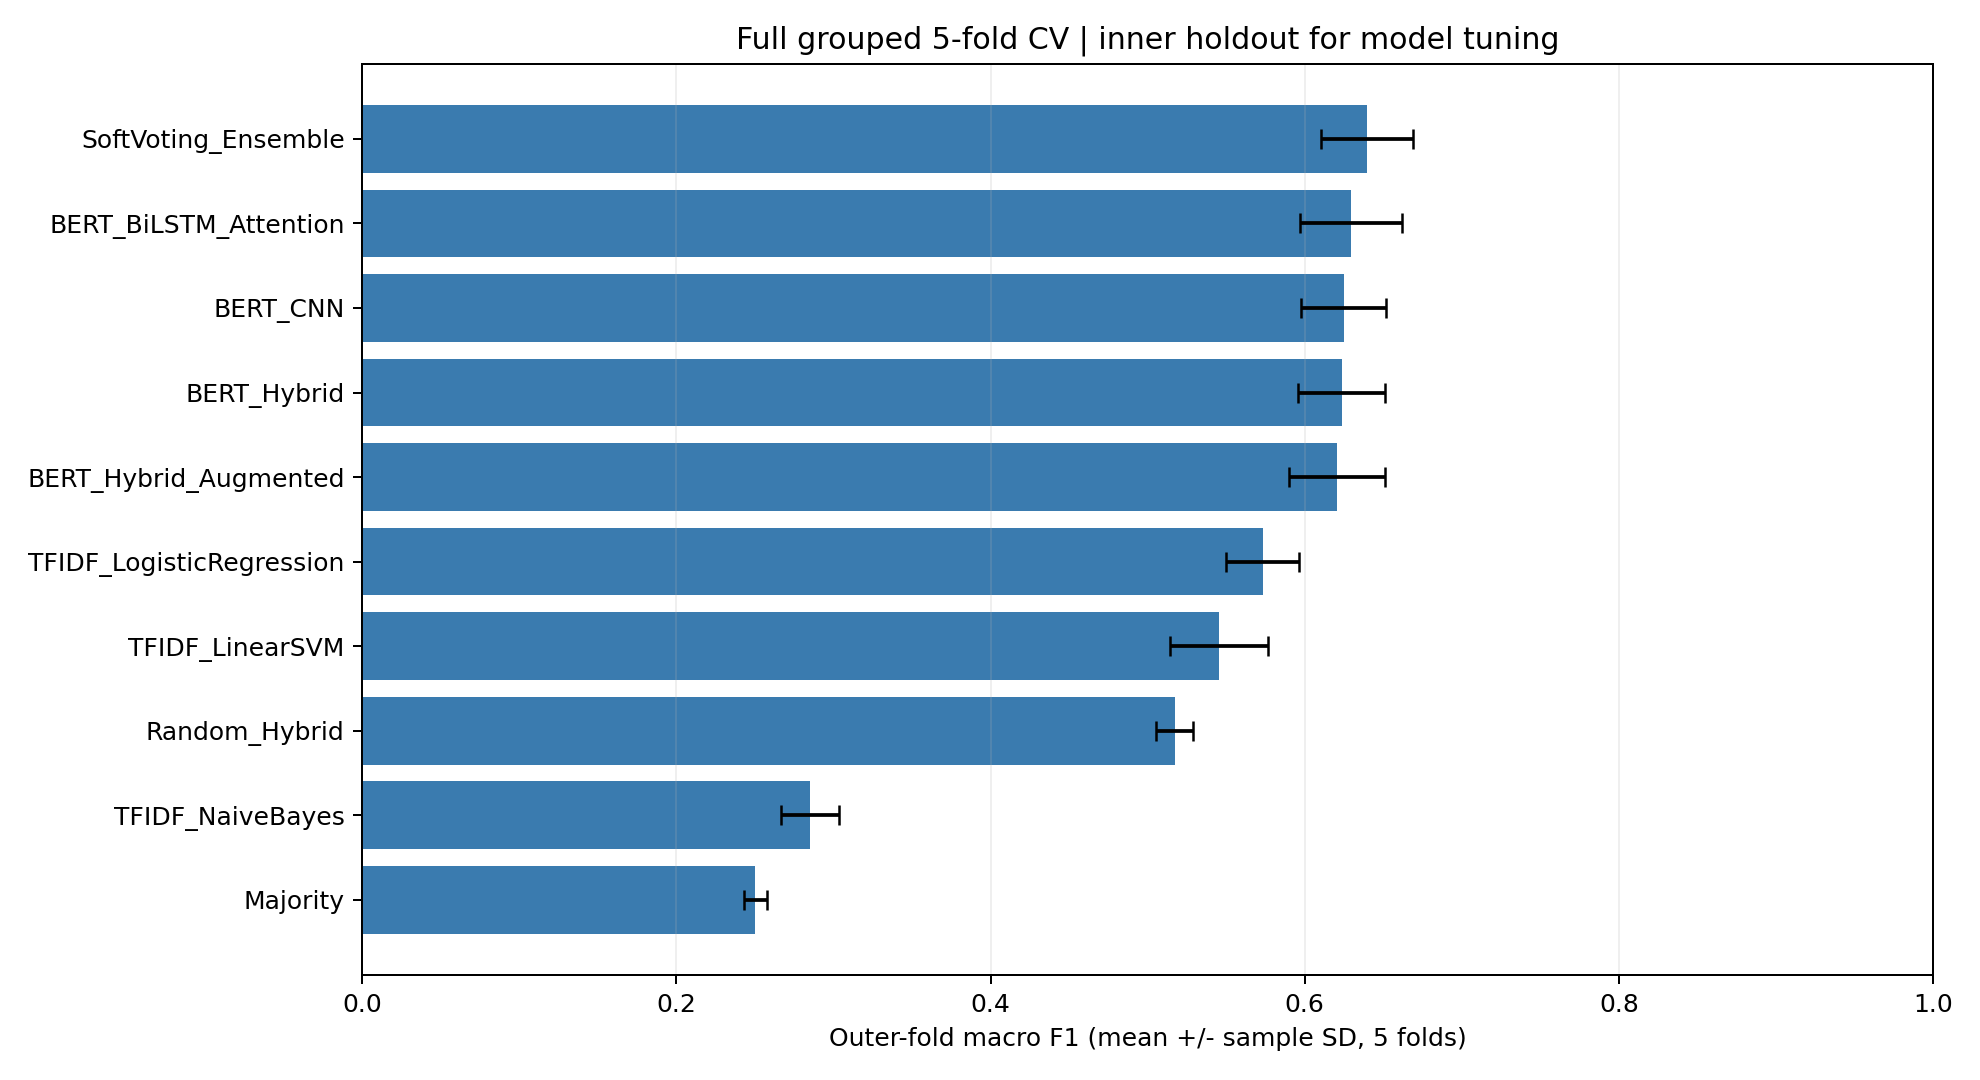

fold,1,2,3,4,5
model,,,,,
BERT_BiLSTM_Attention,0.6194,0.6290,0.6628,0.6543,0.5807
BERT_CNN,0.6190,0.6040,0.6462,0.6590,0.5959
BERT_Hybrid,0.6203,0.5907,0.6272,0.6671,0.6118
BERT_Hybrid_Augmented,0.6150,0.6116,0.6668,0.6278,0.5821
Majority,0.2463,0.2538,0.2413,0.2490,0.2608
Random_Hybrid,0.5207,0.5195,0.4969,0.5254,0.5230
SoftVoting_Ensemble,0.6306,0.6331,0.6803,0.6521,0.6008
TFIDF_LinearSVM,0.5325,0.5876,0.5127,0.5676,0.5267
TFIDF_LogisticRegression,0.5710,0.5832,0.5823,0.5954,0.5347


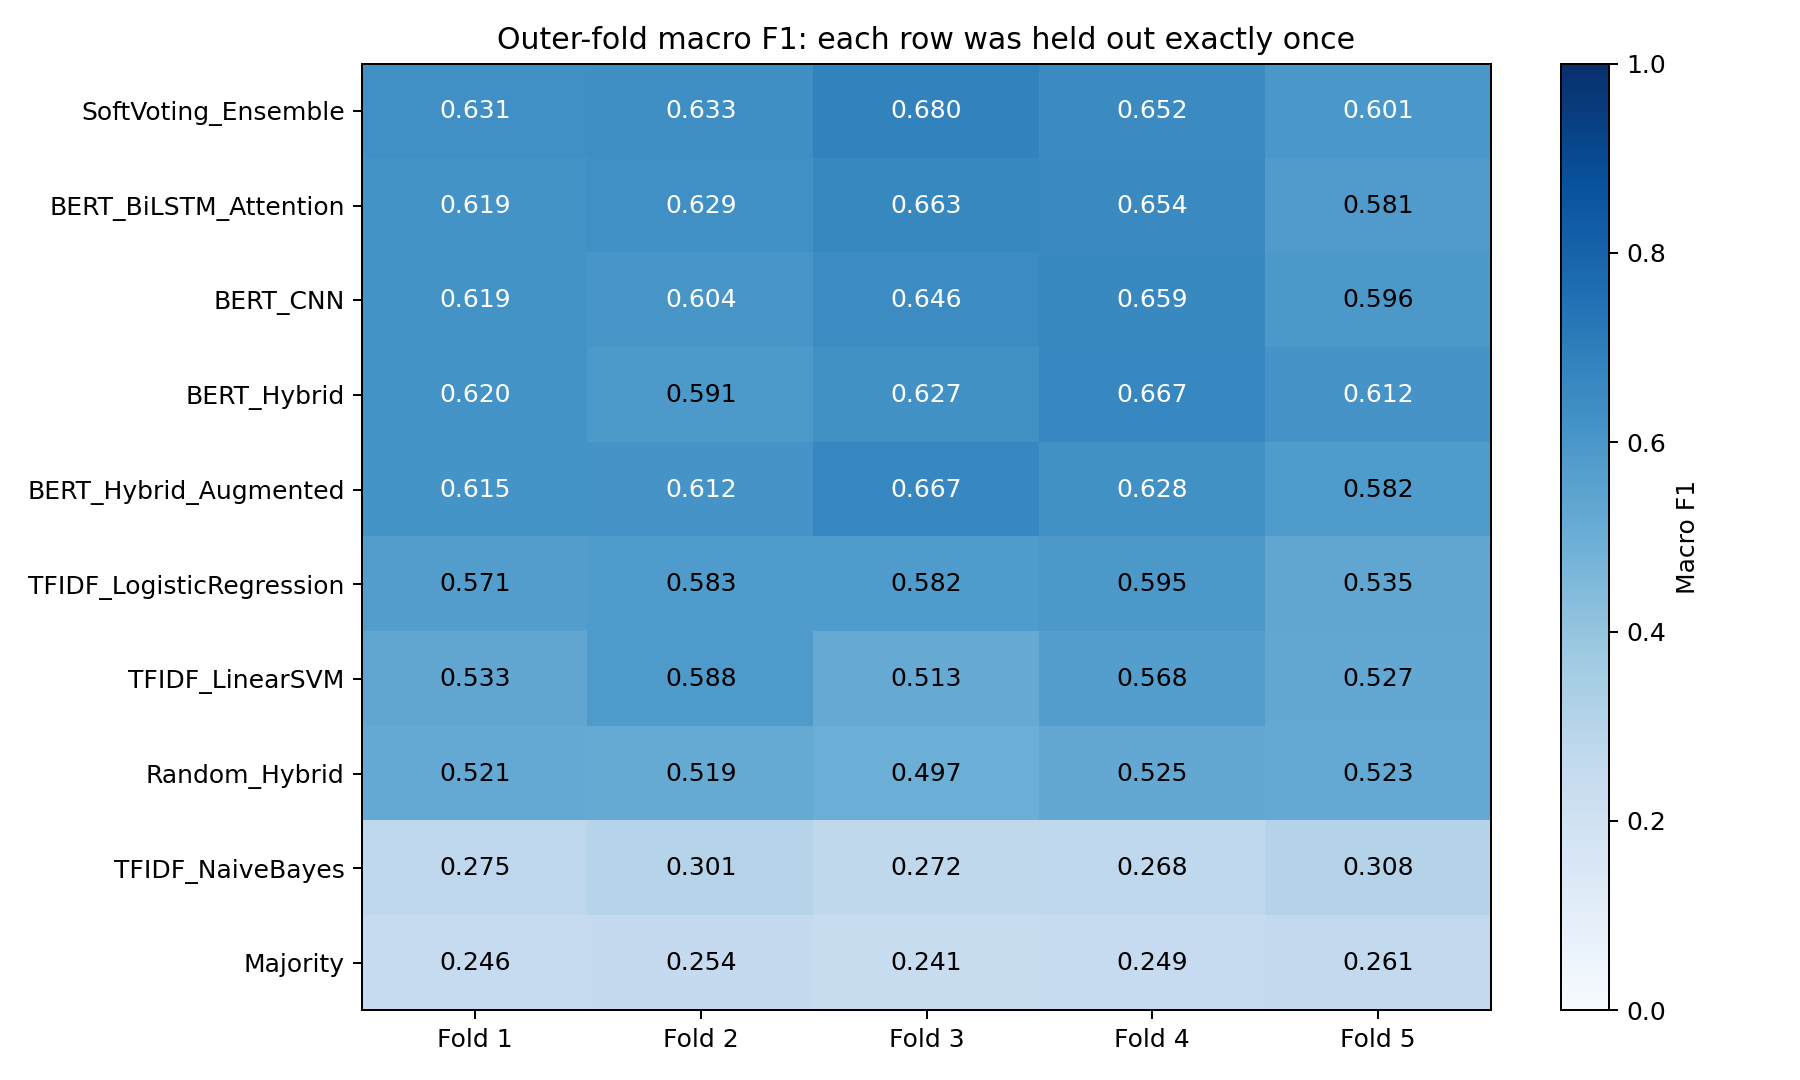

In [5]:
summary = pd.read_csv(CV / 'results/metrics_cv_summary.csv')
metrics = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'roc_auc_ovr_macro']
formatted = pd.DataFrame({'model': summary.model})
for metric in metrics:
    formatted[metric + ' mean ± SD (%)'] = [f'{100*m:.2f} ± {100*s:.2f}' for m,s in zip(summary[metric+'_mean'], summary[metric+'_std'])]
display(formatted)
display(Image(filename=str(CV / 'results/cv_comparison.png')))
fold_metrics = pd.read_csv(CV / 'results/metrics_folds.csv')
display(fold_metrics.pivot(index='model', columns='fold', values='f1_macro').round(4))
display(Image(filename=str(CV / 'results/fold_scores.png')))

## 4. OOF và lựa chọn mô hình

OOF nối dự đoán outer của 5 fold theo đúng mẫu gốc. Metrics OOF được tính trên toàn bộ 3.601 dự đoán;
không đồng nhất với mean của 5 metrics vì kích thước fold khác nhau và F1 không tuyến tính.
Chọn phương pháp theo mean outer Macro-F1, không chọn theo test.

In [6]:
oof_metrics = pd.read_csv(CV / 'results/metrics_oof.csv')
display(oof_metrics.round(4))
selected = read_json(CV / 'models/selected_model.json')
display(selected)
assert selected['model'] == summary.sort_values('f1_macro_mean', ascending=False).iloc[0].model
for name in summary.model:
    oof = pd.read_csv(CV / f'results/predictions_oof_{name}.csv')
    assert len(oof) == 3601 and oof.row_id.is_unique
print('Mọi phương pháp đều có đủ 3.601 dự đoán OOF.')

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro
0,Majority,0.6007,0.2002,0.3333,0.2502,0.4508,0.4844
1,TFIDF_NaiveBayes,0.6096,0.7559,0.3493,0.2843,0.4743,0.7756
2,TFIDF_LogisticRegression,0.6668,0.5752,0.5762,0.5757,0.6672,0.8060
3,TFIDF_LinearSVM,0.6915,0.6261,0.5293,0.5471,0.6575,0.8052
4,Random_Hybrid,0.6129,0.5182,0.5175,0.5176,0.6134,0.7258
5,BERT_CNN,0.7048,0.6197,0.6314,0.6248,0.7077,0.8360
6,BERT_BiLSTM_Attention,0.7120,0.6243,0.6390,0.6303,0.7150,0.8341
7,BERT_Hybrid,0.7029,0.6166,0.6334,0.6227,0.7055,0.8361
8,BERT_Hybrid_Augmented,0.7070,0.6247,0.6229,0.6234,0.7085,0.8322
9,SoftVoting_Ensemble,0.7215,0.6388,0.6425,0.6406,0.7227,0.8464


{'model': 'SoftVoting_Ensemble',
 'criterion': 'mean outer-fold macro F1',
 'folds': 5,
 'f1_macro_mean': 0.6393783200995143,
 'f1_macro_std': 0.02933331116614622,
 'std_ddof': 1,
 'inference': 'equal average of five fold estimators',
 'fold_paths': ['fold_01', 'fold_02', 'fold_03', 'fold_04', 'fold_05']}

Mọi phương pháp đều có đủ 3.601 dự đoán OOF.


## 5. Test chính thức sau khi chọn mô hình

Với mỗi phương pháp, lấy trung bình xác suất của 5 estimator tương ứng rồi đánh giá trên cùng
1.120 mẫu test. Đây là **ensemble qua 5 fold**, không phải chia test thành 5 fold.
Nếu phương pháp là SoftVoting, mỗi fold đã kết hợp ba mạng; sau đó mới trung bình qua fold.
Test này đã được dùng trong thí nghiệm holdout trước, không phải một test mới chưa từng quan sát.
Trong lượt CV này, nhãn test không tham gia training, early stopping hoặc chọn trọng số.

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro
0,Majority,0.6500,0.2167,0.3333,0.2626,0.5121,0.5000
1,TFIDF_NaiveBayes,0.6589,0.7950,0.3503,0.2970,0.5328,0.8443
2,TFIDF_LogisticRegression,0.7366,0.6293,0.6176,0.6186,0.7280,0.8532
3,TFIDF_LinearSVM,0.7384,0.6881,0.5489,0.5618,0.6971,0.8474
4,Random_Hybrid,0.6857,0.5614,0.5343,0.5439,0.6721,0.7737
5,BERT_CNN,0.7777,0.6766,0.6623,0.6613,0.7654,0.8862
6,BERT_BiLSTM_Attention,0.7955,0.7050,0.6876,0.6868,0.7827,0.8921
7,BERT_Hybrid,0.7830,0.6826,0.6650,0.6632,0.7682,0.8893
8,BERT_Hybrid_Augmented,0.7991,0.7216,0.6770,0.6908,0.7852,0.8953
9,SoftVoting_Ensemble,0.7973,0.7125,0.6811,0.6880,0.7835,0.8982


**Phương pháp đã chọn bằng CV:** `SoftVoting_Ensemble`

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro
9,SoftVoting_Ensemble,0.7973,0.7125,0.6811,0.688,0.7835,0.8982


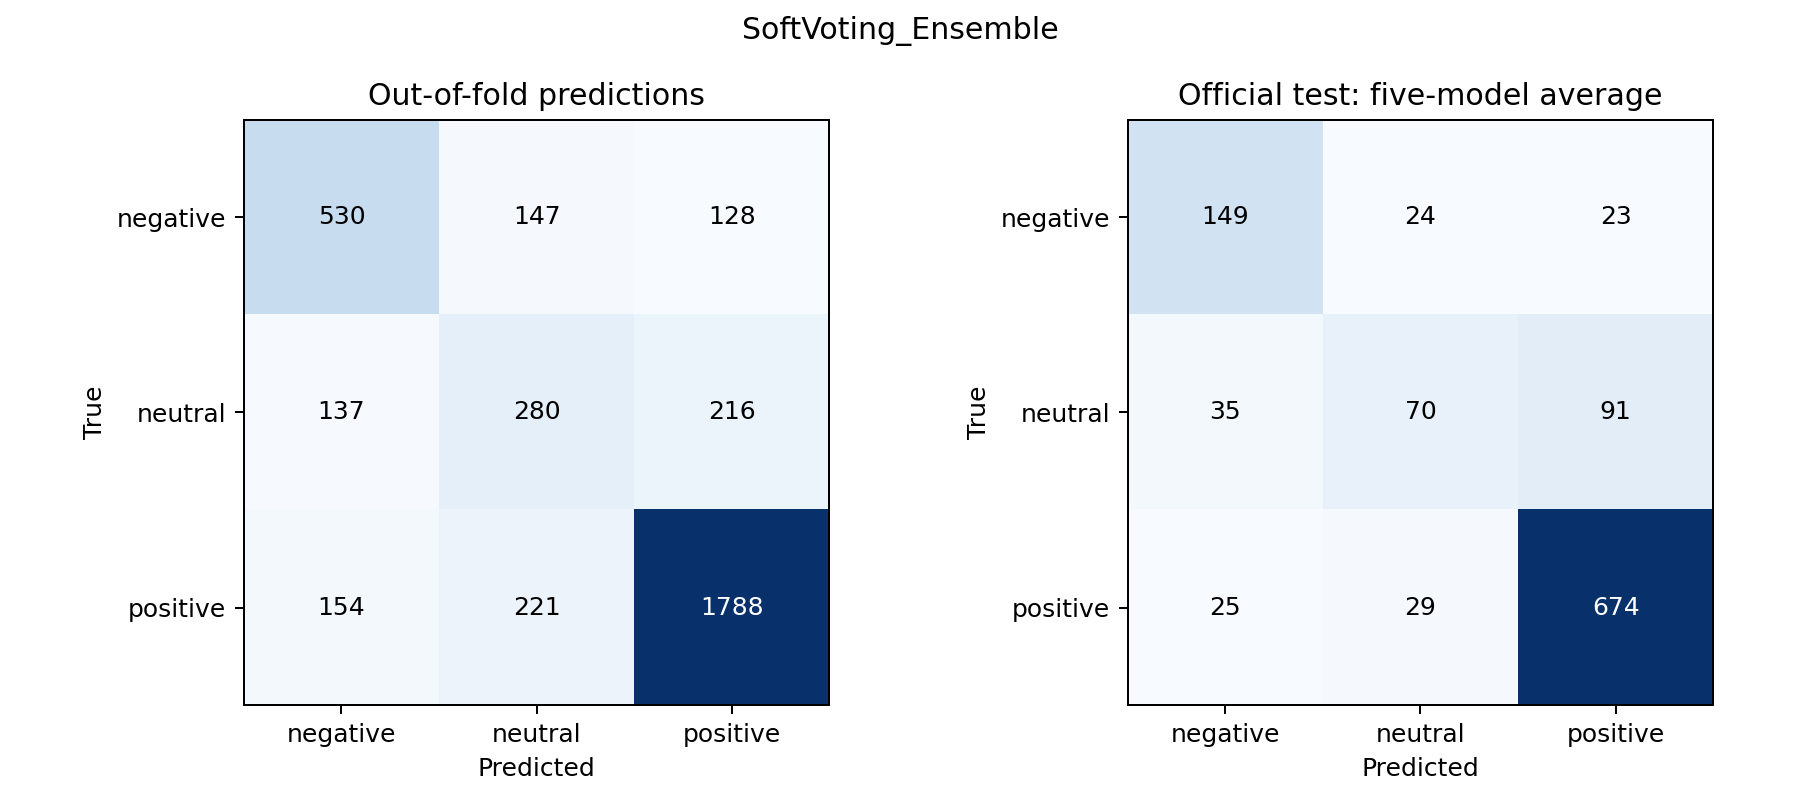

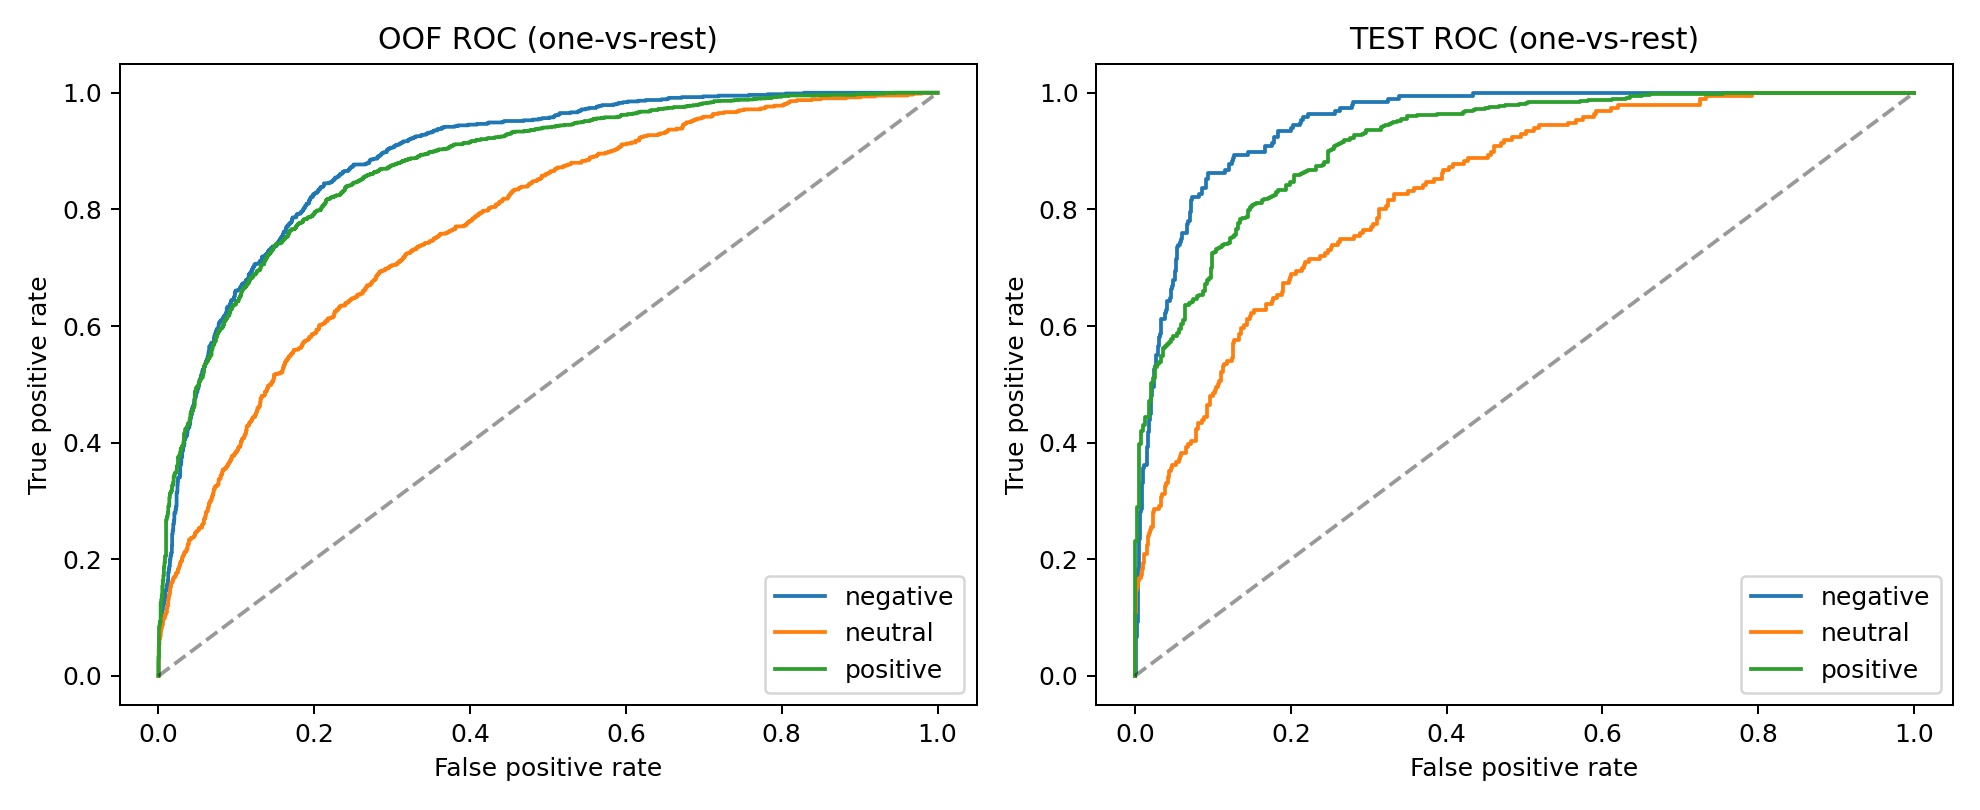

In [7]:
test_metrics = pd.read_csv(CV / 'results/metrics_test.csv')
display(test_metrics.round(4))
display(Markdown(f"**Phương pháp đã chọn bằng CV:** `{selected['model']}`"))
display(test_metrics[test_metrics.model == selected['model']].round(4))
display(Image(filename=str(CV / 'results/selected_confusion.png')))
display(Image(filename=str(CV / 'results/selected_roc.png')))

## 6. Ablation và phân tích lỗi

In [8]:
effects = []
for factor, before, after in [
    ('BERT embedding', 'Random_Hybrid', 'BERT_Hybrid'),
    ('Augmentation', 'BERT_Hybrid', 'BERT_Hybrid_Augmented'),
    ('Soft voting vs augmented Hybrid', 'BERT_Hybrid_Augmented', 'SoftVoting_Ensemble')]:
    a = fold_metrics[fold_metrics.model == before].set_index('fold').f1_macro
    b = fold_metrics[fold_metrics.model == after].set_index('fold').f1_macro
    delta = 100*(b-a)
    effects.append({'Thay đổi': factor, 'Delta F1 trung bình (điểm %)': delta.mean(),
                    'SD delta': delta.std(ddof=1), 'Số fold cải thiện': int((delta>0).sum())})
display(pd.DataFrame(effects).round(3))
errors = pd.read_csv(CV / f"results/errors_{selected['model']}.csv")
display(errors[['text', 'aspect', 'label', 'predicted']].head(10))
print('Số lỗi test:', len(errors))

,Thay đổi,Delta F1 trung bình (điểm %),SD delta,Số fold cải thiện
0,BERT embedding,10.630,2.918,5
1,Augmentation,-0.275,3.321,2
2,Soft voting vs augmented Hybrid,1.872,0.436,5


,text,aspect,label,predicted
0,"Certainly not the best sushi in New York, howe...",place,positive,negative
1,"While there's a decent menu, it shouldn't take...",menu,positive,negative
2,The sangria's - watered down.,sangria,negative,positive
3,The portions of the food that came out were me...,portions of the food,neutral,negative
4,How pretentious and inappropriate for MJ Grill...,lunch,negative,positive
5,How pretentious and inappropriate for MJ Grill...,dinners,negative,positive
6,Two wasted steaks -- what a crime!,steaks,negative,positive
7,The staff should be a bit more friendly.,staff,negative,positive
8,"Entrees include classics like lasagna, fettucc...",Entrees,neutral,positive
9,"Entrees include classics like lasagna, fettucc...",lasagna,neutral,positive


Số lỗi test: 227


## 7. Hạn chế và tái lập

Đủ 5 outer folds nhưng chỉ một seed cho cách chia. Các fold có phần train chồng lấp;
SD không phải sai số của 5 thí nghiệm hoàn toàn độc lập. Chọn mô hình từ bảng CV cũng có thiên lệch lựa chọn;
test cố định giúp đối chiếu nhưng đã được xem ở bài holdout trước. Chưa fine-tune BERT, chưa thêm lớp conflict.
Không suy ra ý nghĩa thống kê chỉ từ chênh lệch mean. Random-vs-BERT còn khác số tham số.

Chạy: `python run_cross_validation.py`; máy chưa có BERT cache: thêm `--allow-download`.
Kiểm tra: `python -m unittest discover -s tests -v`.
Đọc [BAO_CAO_CV.md](BAO_CAO_CV.md) và [README.md](README.md) để xem chi tiết tệp kết quả.
Notebook holdout cũ được giữ lại để đối chiếu, không dùng nhầm số liệu cũ làm kết quả 5-fold.